# Week 4 — Data Quality & Pre-processing II
### Semi-structured data, schema-on-read, and distributed pre-processing with PySpark
**SENG 42293 Big Data Analytics · LO3, LO4**

In Week 3 we cleaned a flat CSV with pandas. Real data often arrives as **nested JSON**, and real data is often **too big for one machine**. Today we:

1. Inspect nested JSON and find corrupt records in plain Python
2. Read it with Spark using an explicit schema (schema-on-read)
3. Flatten, clean and de-duplicate (the Week 3 pipeline, now in PySpark)
4. See narrow vs wide transformations and the shuffle in the query plan
5. Run the in-class **word count** (Map → Shuffle → Reduce) on 4 partitions
6. Engineer features at scale with a Spark ML pipeline
7. Store the result as partitioned Parquet

**Data:** `data/raw_json_sample/hotels_00.jsonl` is one of the five raw files of the semester project (60 hotels, one nested hotel per line). The full pipeline in the *Pipeline Guide* uses all five files, so numbers there are larger.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

## 1. Look at the raw JSON (plain Python)
One hotel per line. Each hotel has a nested `location` object and a `reviews` array.

In [2]:
import json
path = "data/raw_json_sample/hotels_00.jsonl"
lines = open(path).read().splitlines()
print("lines in file:", len(lines))
first = json.loads(lines[0])
print(json.dumps({k: (v if k != "reviews" else v[:2]) for k, v in first.items()}, indent=2)[:1200])
print("... reviews in this hotel:", len(first["reviews"]))

lines in file: 60
{
  "hotel_id": "H-1000",
  "name": "Royal Inn 0",
  "location": {
    "city": "Nuwara Eliya",
    "lat": 6.9634,
    "lon": 80.7662
  },
  "stars": 4,
  "reviews": [
    {
      "review_id": "H-1000-R000",
      "user": "u572",
      "rating": 5,
      "text": "Friendly staff, good value, highly recommended, peaceful location.",
      "date": "2023-08-17",
      "tags": [
        "family"
      ],
      "helpful_votes": 16
    },
    {
      "review_id": "H-1000-R001",
      "user": "u903",
      "rating": 4.0,
      "text": "Highly recommended, peaceful location, great view.",
      "date": "2024-03-05",
      "helpful_votes": 13
    }
  ]
}
... reviews in this hotel: 45


### Find corrupt lines before Spark does
One bad line must not kill a big job. In Python we can try to parse each line and *quarantine* failures.

In [3]:
good, bad = [], []
for i, ln in enumerate(lines):
    try: good.append(json.loads(ln))
    except json.JSONDecodeError as e: bad.append((i, ln[:60] + "...", str(e)[:50]))
print(f"parsed OK: {len(good)}   corrupt: {len(bad)}")
for b in bad: print("quarantine ->", b)
RES["py_lines"], RES["py_corrupt"] = len(lines), len(bad)

parsed OK: 58   corrupt: 2
quarantine -> (28, '{"hotel_id": "H-1140", "name": "Royal Residency 140", "locat...', 'Unterminated string starting at: line 1 column 340')
quarantine -> (36, '{"hotel_id": "H-1180", "name": "Sunrise Residency 180", "loc...', 'Unterminated string starting at: line 1 column 602')


### Key presence and type drift
Semi-structured means *each record carries its own structure*. Let us see how irregular the reviews are.

In [4]:
from collections import Counter
key_counts, rating_types = Counter(), Counter()
n_rev = 0
for h in good:
    for r in h["reviews"]:
        n_rev += 1; key_counts.update(r.keys())
        rating_types[type(r["rating"]).__name__ if "rating" in r else "MISSING KEY"] += 1
print("reviews:", n_rev)
print(pd.Series(key_counts).rename("records having key").to_frame().assign(pct=lambda d: (100 * d.iloc[:, 0] / n_rev).round(1)))
print("\nrating value types:", dict(rating_types))

reviews: 3617
               records having key    pct
review_id                    3617  100.0
user                         3617  100.0
rating                       3421   94.6
text                         3617  100.0
date                         3617  100.0
tags                         2143   59.2
helpful_votes                1799   49.7

rating value types: {'int': 542, 'float': 2530, 'NoneType': 136, 'MISSING KEY': 196, 'str': 213}


**Takeaway:** `rating` is sometimes a number, sometimes a string, sometimes `null`, sometimes absent. `tags` and `helpful_votes` are optional. Code that assumes a fixed table will crash.

## 2. Start Spark and read with an explicit schema (schema-on-read)

In [5]:
import sys
os.environ["PYSPARK_PYTHON"] = sys.executable           # workers must use the same Python as the driver
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import *
spark = (SparkSession.builder.master("local[*]").appName("week4")
         .config("spark.ui.enabled", "false").config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| default parallelism:", spark.sparkContext.defaultParallelism)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 08:31:32 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 08:31:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 08:31:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | default parallelism: 2


In [6]:
review = StructType([
    StructField("review_id", StringType()), StructField("user", StringType()),
    StructField("rating", StringType()),            # STRING on purpose: absorbs 4.5, "4.5", "N/A", null
    StructField("text", StringType()), StructField("date", StringType()),
    StructField("tags", ArrayType(StringType())), StructField("helpful_votes", IntegerType())])
schema = StructType([
    StructField("hotel_id", StringType()), StructField("name", StringType()),
    StructField("location", StructType([StructField("city", StringType()), StructField("lat", DoubleType()), StructField("lon", DoubleType())])),
    StructField("stars", IntegerType()), StructField("reviews", ArrayType(review)),
    StructField("_corrupt", StringType())])

raw = (spark.read.schema(schema).option("mode", "PERMISSIVE")
       .option("columnNameOfCorruptRecord", "_corrupt").json(path).cache())
n_lines = raw.count(); n_bad = raw.filter(F.col("_corrupt").isNotNull()).count()
print(f"lines={n_lines}  corrupt={n_bad}  (Python found {RES['py_corrupt']})")
raw.printSchema()

lines=60  corrupt=2  (Python found 2)
root
 |-- hotel_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- location: struct (nullable = true)
 |    |-- city: string (nullable = true)
 |    |-- lat: double (nullable = true)
 |    |-- lon: double (nullable = true)
 |-- stars: integer (nullable = true)
 |-- reviews: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- review_id: string (nullable = true)
 |    |    |-- user: string (nullable = true)
 |    |    |-- rating: string (nullable = true)
 |    |    |-- text: string (nullable = true)
 |    |    |-- date: string (nullable = true)
 |    |    |-- tags: array (nullable = true)
 |    |    |    |-- element: string (containsNull = true)
 |    |    |-- helpful_votes: integer (nullable = true)
 |-- _corrupt: string (nullable = true)



`PERMISSIVE` mode keeps the broken line in the `_corrupt` column instead of failing the job. We **count** the rejects: silent data loss is the worst kind.

## 3. Flatten, clean, de-duplicate
*Nested objects become columns (dot notation); arrays become rows (`explode`).*  Always compare row counts.

In [7]:
bronze = raw.filter(F.col("_corrupt").isNull()).drop("_corrupt")
flat = (bronze.select("hotel_id", F.col("name").alias("hotel_name"), "stars", F.col("location.city").alias("city"),
                      F.explode("reviews").alias("r")).select("hotel_id", "hotel_name", "stars", "city", "r.*"))
n_hotels, n_flat = bronze.count(), flat.count()
print(f"hotels: {n_hotels}  ->  review rows after explode: {n_flat}   (x{n_flat / n_hotels:.1f})")
flat.select("hotel_id", "city", "review_id", "rating", "date").show(5, truncate=False)

hotels: 58  ->  review rows after explode: 3617   (x62.4)


+--------+------------+-----------+------+----------+
|hotel_id|city        |review_id  |rating|date      |
+--------+------------+-----------+------+----------+
|H-1000  |Nuwara Eliya|H-1000-R000|5     |2023-08-17|
|H-1000  |Nuwara Eliya|H-1000-R001|4.0   |2024-03-05|
|H-1000  |Nuwara Eliya|H-1000-R002|2.5   |2025-02-20|
|H-1000  |Nuwara Eliya|H-1000-R003|3.0   |2025-04-29|
|H-1000  |Nuwara Eliya|H-1000-R004|5     |2024-01-15|
+--------+------------+-----------+------+----------+
only showing top 5 rows



flattened=3617  after dedup=3577 (removed 40)  valid rating=3131  unparsed dates=0


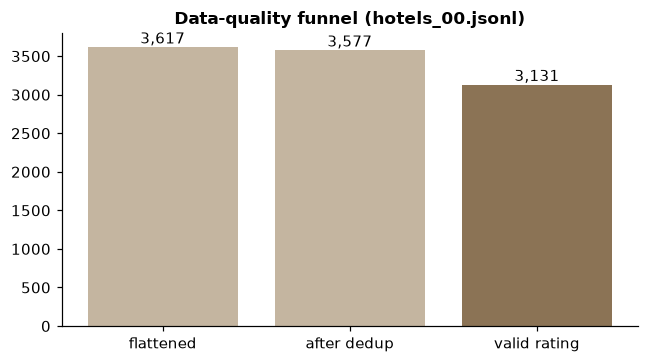

In [8]:
dedup = flat.dropDuplicates(["review_id"])
n_dedup = dedup.count()

rating = F.col("rating").cast("double")               # "N/A" -> null, "4.5" -> 4.5
silver = (dedup.withColumn("rating_clean", F.when(rating.between(1, 5), rating))
               .withColumn("review_date", F.coalesce(F.to_date("date", "yyyy-MM-dd"), F.to_date("date", "dd/MM/yyyy"))))
n_valid = silver.filter(F.col("rating_clean").isNotNull()).count()
n_nodate = silver.filter(F.col("review_date").isNull()).count()
print(f"flattened={n_flat}  after dedup={n_dedup} (removed {n_flat-n_dedup})  valid rating={n_valid}  unparsed dates={n_nodate}")
RES.update(hotels=n_hotels, flat=n_flat, dedup=n_dedup, valid=n_valid, lines=n_lines, corrupt=n_bad)

fig, ax = plt.subplots(figsize=(6, 3.4))
vals = [n_flat, n_dedup, n_valid]
ax.bar(["flattened", "after dedup", "valid rating"], vals, color=[ACCL, ACCL, ACC])
for i, v in enumerate(vals): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Data-quality funnel (hotels_00.jsonl)"); save("w04_funnel")

### Why the rating cast works
`cast("double")` turns `"4.5"` into `4.5` and `"N/A"` into `null`; `F.when(between(1, 5), …)` turns out-of-range values (0, 11, -1) into `null`. Two date formats are handled by trying each and taking the first that parses (`coalesce`).

In [9]:
silver.groupBy("rating").count().orderBy(F.desc("count")).show(12)       # the raw string values, including N/A and out-of-range

+------+-----+
|rating|count|
+------+-----+
|   3.5|  576|
|   4.0|  507|
|   3.0|  506|
|     5|  484|
|   4.5|  441|
|  NULL|  325|
|   2.5|  312|
|   2.0|  179|
|   N/A|   91|
|   1.5|   81|
|     1|   45|
|    -1|   13|
+------+-----+
only showing top 12 rows



## 4. Lazy evaluation, narrow vs wide transformations

In [10]:
import time
t0 = time.time()
plan = silver.filter(F.col("city") == "Kandy").withColumn("len", F.length("text")).groupBy("hotel_id").agg(F.avg("len").alias("avg_len"))
print(f"building the plan took {time.time()-t0:.3f}s  (nothing has run: transformations are lazy)")
t0 = time.time(); n = plan.count(); print(f"count() = {n} hotels, action took {time.time()-t0:.2f}s")

building the plan took 0.177s  (nothing has run: transformations are lazy)


count() = 11 hotels, action took 0.86s


Look for `Exchange` in the plan: that is a **shuffle**, produced by the wide transformation `groupBy`. `filter` and `withColumn` are narrow and need no exchange.

In [11]:
plan.explain()
print("partitions of silver:", silver.rdd.getNumPartitions(), "| after groupBy (shuffle partitions):", plan.rdd.getNumPartitions())

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[hotel_id#2006], functions=[avg(len#1710)])
   +- Exchange hashpartitioning(hotel_id#2006, 8), ENSURE_REQUIREMENTS, [plan_id=1568]
      +- HashAggregate(keys=[hotel_id#2006], functions=[partial_avg(len#1710)])
         +- Project [hotel_id#2006, length(text#2018) AS len#1710]
            +- Filter (isnotnull(city#2012) AND (city#2012 = Kandy))
               +- SortAggregate(key=[review_id#386], functions=[first(hotel_id#0, false), first(city#377, false), first(text#389, false)])
                  +- Sort [review_id#386 ASC NULLS FIRST], false, 0
                     +- Exchange hashpartitioning(review_id#386, 8), ENSURE_REQUIREMENTS, [plan_id=1561]
                        +- SortAggregate(key=[review_id#386], functions=[partial_first(hotel_id#0, false), partial_first(city#377, false), partial_first(text#389, false)])
                           +- Sort [review_id#386 ASC NULLS FIRST], false, 0
              

partitions of silver: 1 | after groupBy (shuffle partitions): 1


## 5. In-class activity: Word count (Map → Shuffle → Reduce)

In [12]:
import re
from collections import Counter
parts = [
 "Big data is not just about size. Every day, hotels, airlines and travellers generate huge volumes of data, and this data arrives in many formats. A single review can contain text, ratings and dates.",
 "Companies collect this data to understand what customers want. When data grows beyond one machine, the work must be shared across many machines, and each machine processes only a small part of the data.",
 "Spark splits the data into partitions, and each partition is processed in parallel. The results from every partition are then combined into one final result. This is how a cluster counts millions of words quickly.",
 "Counting words is the classic first example of big data processing. Count each word in every partition, then add the counts together, and the final result is the same as counting on one machine."]
tok = lambda t: re.findall(r"[a-z']+", t.lower())

# (a) one machine
single = Counter(w for p in parts for w in tok(p))
# (b) four partitions in parallel: map, then reduceByKey
sc = spark.sparkContext
rdd = sc.parallelize(parts, 4)
counts = rdd.flatMap(tok).map(lambda w: (w, 1)).reduceByKey(lambda a, b: a + b)
cluster = dict(counts.collect())
assert cluster == dict(single), "partitioned result must equal the single-machine result"
print("partitions:", rdd.getNumPartitions(), "| words:", sum(single.values()), "| distinct:", len(single))
print("top:", counts.sortBy(lambda x: (-x[1], x[0])).take(5))

partitions: 4 | words: 137 | distinct: 86


top: [('data', 8), ('the', 8), ('and', 6), ('is', 5), ('of', 4)]


In [13]:
# What did each worker (partition) count locally BEFORE the shuffle?
def local_counts(idx, it):
    c = Counter(w for line in it for w in tok(line))
    yield idx, {"data": c["data"], "the": c["the"], "n_words": sum(c.values())}
for idx, d in rdd.mapPartitionsWithIndex(local_counts).collect(): print(f"worker {idx+1}:", d)
RES["wc_total"], RES["wc_distinct"], RES["wc_data"], RES["wc_the"] = sum(single.values()), len(single), single["data"], single["the"]

worker 1: {'data': 3, 'the': 0, 'n_words': 34}
worker 2: {'data': 3, 'the': 2, 'n_words': 34}
worker 3: {'data': 1, 'the': 2, 'n_words': 35}
worker 4: {'data': 1, 'the': 4, 'n_words': 34}


**Exercise 1.** Why does Spark's `reduceByKey` beat collecting every `(word, 1)` pair to the driver and adding them there? *(Hint: what travels over the network?)*

## 6. Feature engineering at scale

In [14]:
from pyspark.sql.window import Window
rated = silver.filter(F.col("rating_clean").isNotNull())
w = Window.partitionBy("hotel_id")
feat = (rated.withColumn("month", F.month("review_date"))
             .withColumn("weekday", F.date_format("review_date", "E"))
             .withColumn("n_words", F.size(F.split("text", r"\\s+")))
             .withColumn("hotel_avg", F.round(F.avg("rating_clean").over(w), 3))        # window aggregate
             .withColumn("hotel_n", F.count("*").over(w)))
feat.select("hotel_id", "rating_clean", "hotel_avg", "hotel_n", "month", "weekday", "n_words").show(5)

+--------+------------+---------+-------+-----+-------+-------+
|hotel_id|rating_clean|hotel_avg|hotel_n|month|weekday|n_words|
+--------+------------+---------+-------+-----+-------+-------+
|  H-1000|         5.0|    3.931|     36|    8|    Thu|      1|
|  H-1000|         4.0|    3.931|     36|    3|    Tue|      1|
|  H-1000|         2.5|    3.931|     36|    2|    Thu|      1|
|  H-1000|         3.0|    3.931|     36|    4|    Tue|      1|
|  H-1000|         5.0|    3.931|     36|    1|    Mon|      1|
+--------+------------+---------+-------+-----+-------+-------+
only showing top 5 rows



In [15]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, Bucketizer
bucket = Bucketizer(splits=[-float("inf"), 8, 12, float("inf")], inputCol="n_words", outputCol="len_bucket")
stages = [StringIndexer(inputCol="city", outputCol="city_ix", handleInvalid="keep"),
          OneHotEncoder(inputCols=["city_ix"], outputCols=["city_oh"]),
          VectorAssembler(inputCols=["city_oh", "stars", "n_words", "hotel_avg"], outputCol="raw_features"),
          StandardScaler(inputCol="raw_features", outputCol="features", withMean=False, withStd=True)]
pipe = Pipeline(stages=stages).fit(feat)              # fit on training data only in a real model!
out = pipe.transform(feat)
out.select("city", "stars", "n_words", "features").show(3, truncate=60)

+------------+-----+-------+------------------------------------------------------------+
|        city|stars|n_words|                                                    features|
+------------+-----+-------+------------------------------------------------------------+
|Nuwara Eliya|    4|      1|(9,[0,6,7,8],[2.3818379833537966,4.5353034179295815,0.0,1...|
|Nuwara Eliya|    4|      1|(9,[0,6,7,8],[2.3818379833537966,4.5353034179295815,0.0,1...|
|Nuwara Eliya|    4|      1|(9,[0,6,7,8],[2.3818379833537966,4.5353034179295815,0.0,1...|
+------------+-----+-------+------------------------------------------------------------+
only showing top 3 rows



**Reminder:** `fit` learns the encoder categories and scaling statistics. Fit on *training* data only; apply `transform` to test data, otherwise information leaks from test to train.

## 7. Store as partitioned Parquet and see partition pruning

In [16]:
import tempfile, shutil
tmp = tempfile.mkdtemp()
silver.drop("rating").withColumnRenamed("rating_clean", "rating").write.mode("overwrite").partitionBy("city").parquet(tmp + "/silver")
print(sorted(os.listdir(tmp + "/silver"))[:8])
back = spark.read.parquet(tmp + "/silver")
back.filter(F.col("city") == "Kandy").explain()          # look for PartitionFilters: only the city=Kandy folder is read
print("rows back:", back.count())
shutil.rmtree(tmp)

['._SUCCESS.crc', '_SUCCESS', 'city=Colombo', 'city=Ella', 'city=Galle', 'city=Kandy', 'city=Nuwara Eliya', 'city=Sigiriya']
== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [hotel_id#4024,hotel_name#4025,stars#4026,review_id#4027,user#4028,text#4029,date#4030,tags#4031,helpful_votes#4032,rating#4033,review_date#4034,city#4035] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/tmp/tmp1qjwgg_p/silver], PartitionFilters: [isnotnull(city#4035), (city#4035 = Kandy)], PushedFilters: [], ReadSchema: struct<hotel_id:string,hotel_name:string,stars:int,review_id:string,user:string,text:string,date:...




rows back: 3577


## 8. Exercises
1. How many reviews had `rating` stored as a string? *(Use the Python counter and Spark and compare.)*
2. Add a quality gate: fail if more than 2% of lines are corrupt.
3. Replace the `n_words` feature with a `has_tags` flag. Does the Spark plan change?
4. Run the full pipeline from the **Pipeline Guide** on all five files and compare the funnel.
5. Change `spark.sql.shuffle.partitions` to 2 and 200. What happens to the plan and the runtime for this tiny data? Why?

In [17]:
spark.stop()
json.dump(RES, open("results/w04.json", "w"), indent=1); print(RES)

{'py_lines': 60, 'py_corrupt': 2, 'hotels': 58, 'flat': 3617, 'dedup': 3577, 'valid': 3131, 'lines': 60, 'corrupt': 2, 'wc_total': 137, 'wc_distinct': 86, 'wc_data': 8, 'wc_the': 8}
